# Solid mechanics
*Plasticity at an integration point: the radial return*

When a metal is loaded past its yield stress it flows, and when the load is taken off it keeps some of the strain. A finite-element code finds the stress at every integration point of every element, at every step, with a small routine called the **return map**. This page writes that routine for von Mises (J2) plasticity with linear isotropic hardening, runs one lane per integration point over a sweep of strain paths, and takes the consistent tangent the solver needs by differentiating it.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The material, once

Small strains, rate independent, an isotropic elastic law and a von Mises yield surface. The model leaves out kinematic hardening (so no Bauschinger effect: real metals under reversed load soften early on reversal), damage, large deformation and temperature; for a full material library, reach for the one in your finite-element code.

- Strain `eps` and stress `sigma` are symmetric tensors, stored as six numbers: the components 11, 22, 33, 12, 13, 23 (tensor components, so the shear entry is `eps_12`, not the engineering shear). The 6 x 6 tangent below is `d sigma / d eps` in this tensor-shear storage; an Abaqus/UMAT-style code stores the engineering shear `gamma = 2 eps_12`, and needs the three shear columns halved. That factor of two is the classic bug.
- The strain splits into an elastic and a plastic part. The stress is the elastic law applied to the elastic part: `sigma = kappa tr(eps) I + 2 mu dev(eps - eps_p)`, with the bulk modulus `kappa` and the shear modulus `mu` from `E` and `nu`.
- Yielding follows the **von Mises** rule: the surface is `f = ||s|| - sqrt(2/3) (sigma_y + H alpha) = 0`, where `s` is the deviatoric stress, `alpha` the accumulated equivalent plastic strain and `H` the hardening modulus. Flow is along the deviator, so it does not change the volume.
- Units: MPa. Steel-like numbers: `E = 200 GPa`, `nu = 0.3`, `sigma_y = 250 MPa`, `H = 2 GPa`.

The **radial return** is the standard step: given the strain at the end of a step, form the *trial* stress as if the step were elastic. If the trial lies inside the surface (`f_trial <= 0`), keep it. If it lies outside, move it back along the radius to the surface, and grow `eps_p` and `alpha` by the amount moved.

Declare the material's words as a `KernelKind` once: which strain history the point follows, the probe that will give the tangent, and the four material constants.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Param, Scalar, Table, Vector
from hawk.ext import DATA_ONLY, KernelKind

NSTEP = 40                                                  # strain steps per history
SQ23 = float(np.sqrt(2.0 / 3.0))
E_MOD, NU, SIGMA_Y, HARD = 200_000.0, 0.3, 250.0, 2_000.0   # MPa, -, MPa, MPa
MU, KAPPA = E_MOD / (2 * (1 + NU)), E_MOD / (3 * (1 - 2 * NU))


class Material(KernelKind, slug="material"):
    path: Index         # which strain history this integration point follows (a row of the strain table)
    d_eps: Vector[6]    # an extra strain added at the last step: the probe for the tangent
    E: Param            # Young's modulus (MPa)
    nu: Param           # Poisson's ratio
    sigma_y: Param      # initial yield stress (MPa)
    hard: Param         # linear isotropic hardening modulus (MPa): yield stress = sigma_y + hard * alpha
    guard = DATA_ONLY

Material

__main__.Material

## One integration point

Each lane takes the strain history of its point from a table, 40 steps of six numbers, and walks it with the return map. The natural `if / else` on the trial yield function decides elastic against plastic, and a plastic step solves for the plastic multiplier `dgamma = f_trial / (2 mu + 2 H / 3)` and returns radially. The tensor arithmetic lives in small plain-Python helpers that run once, when the kernel is traced.

The kernel returns the final stress and plastic strain, the stress history of the axial and shear entries, and three numbers for the checks below: how far each plastic return ended from the yield surface, the trial deviator of the last step and its plastic multiplier. `d_eps` is zero in a normal run; it adds a strain to the last step, and that is how the tangent will be probed.

In [4]:
def zeros(n):
    return m.vec(*[0.0] * n)


def strain_at(strain, path, k, d_eps):
    # the six strain components e11 e22 e33 e12 e13 e23 of step k, plus the probe at the last step
    base = (path * NSTEP + k) * 6
    last = m.where(k == NSTEP - 1, 1.0, 0.0)
    return m.vec(*[strain.at(base + j) + last * d_eps[j] for j in range(6)])


def norm(s):                                                # the tensor norm of a symmetric tensor stored as 11 22 33 12 13 23
    return m.sqrt(s[0] * s[0] + s[1] * s[1] + s[2] * s[2] + 2.0 * (s[3] * s[3] + s[4] * s[4] + s[5] * s[5]))


def deviator(a):
    third = (a[0] + a[1] + a[2]) / 3.0
    return m.vec(a[0] - third, a[1] - third, a[2] - third, a[3], a[4], a[5])


def sphere(a, kappa):                                       # the pressure part of the stress: kappa tr(eps) on the diagonal
    p = kappa * (a[0] + a[1] + a[2])
    return m.vec(p, p, p, 0.0, 0.0, 0.0)


@Material
def update(path, d_eps, E, nu, sigma_y, hard, strain: Table[Scalar],
           stress: Mutable[Vector[6]], eps_p: Mutable[Vector[6]], alpha_out: Mutable[Scalar],
           axial: Mutable[Vector[NSTEP]], shear: Mutable[Vector[NSTEP]],
           s_trial_last: Mutable[Vector[6]], dgamma_last: Mutable[Scalar], off_surface: Mutable[Scalar], plastic_steps: Mutable[Scalar]):
    mu = E / (2.0 * (1.0 + nu))
    kappa = E / (3.0 * (1.0 - 2.0 * nu))
    ep = zeros(6)
    alpha = 0.0
    axial_hist = zeros(NSTEP)
    shear_hist = zeros(NSTEP)
    s_tr = zeros(6)
    dg = 0.0
    sigma = zeros(6)
    worst = 0.0
    count = 0.0
    for k in range(NSTEP):
        eps = strain_at(strain, path, k, d_eps)
        s_tr = 2.0 * mu * deviator(eps - ep)                              # trial: the step is elastic
        f_tr = norm(s_tr) - SQ23 * (sigma_y + hard * alpha)               # trial yield function
        if f_tr > 0.0:                                                    # plastic: return radially to the surface
            dg = f_tr / (2.0 * mu + 2.0 * hard / 3.0)
            count = count + 1.0
        else:                                                             # elastic: keep the trial stress
            dg = 0.0
        flow = s_tr * (1.0 / m.sqrt(norm(s_tr) * norm(s_tr) + 1e-300))   # unit direction of the trial deviator
        ep = ep + dg * flow
        alpha = alpha + SQ23 * dg
        s = s_tr - 2.0 * mu * dg * flow
        sigma = s + sphere(eps, kappa)
        gap = m.abs(norm(s) - SQ23 * (sigma_y + hard * alpha)) / sigma_y  # distance from the yield surface after the return
        worst = m.where(dg > 0.0, m.where(gap > worst, gap, worst), worst)
        axial_hist[k] = sigma[0]
        shear_hist[k] = sigma[3]
    stress = sigma
    eps_p = ep
    alpha_out = alpha
    axial = axial_hist
    shear = shear_hist
    s_trial_last = s_tr
    dgamma_last = dg
    off_surface = worst
    plastic_steps = count


update

<Kernel update slots=16>

## A sweep of strain paths

Three kinds of path, five amplitudes each, so 15 integration points in one call:

- **load-unload**: pull in uniaxial stress to a strain, then back to zero;
- **cyclic**: pull and push between the strain limits, twice;
- **shear**: a pure shear strain, out, back and through to the other side.

The yield strain is 0.00125, so the amplitudes are 1.6 to 8 times the yield strain. For the uniaxial paths the *lateral* strains must be those of a uniaxial *stress* state; a finite-element code gets them from the equilibrium of the neighbouring elements, and here they are tabulated from a one-dimensional model, which is also the reference below. The table is what a solver hands the material routine: one strain history per point.

In [5]:
AMPS = np.array([0.002, 0.004, 0.006, 0.008, 0.010])        # strain amplitudes: the yield strain is 0.00125
KINDS = ("load-unload", "cyclic", "shear")
WAYPOINTS = {"load-unload": [0, 1, 0], "cyclic": [0, 1, -1, 1, -1], "shear": [0, 1, 0, -1, 0]}


def drive(kind, amp):
    # the driving strain at each of the NSTEP steps: piecewise linear through the waypoints, one row per amplitude
    s = np.arange(1, NSTEP + 1) / NSTEP
    w = WAYPOINTS[kind]
    return np.asarray(amp)[:, None] * np.interp(s, np.linspace(0, 1, len(w)), w)[None, :]


def uniaxial_reference(e):
    # the one-dimensional model of uniaxial stress with linear isotropic hardening: exact for any step. Returns stress and lateral strain
    sig, alpha, plastic = np.zeros(len(e)), np.zeros(len(e)), np.zeros(len(e))
    stress, lateral = [], []
    last = np.zeros(len(e))
    for k in range(e.shape[1]):
        trial = sig + E_MOD * (e[:, k] - last)
        f = np.abs(trial) - (SIGMA_Y + HARD * alpha)
        dg = np.where(f > 0, f / (E_MOD + HARD), 0.0)
        sg = np.sign(trial)
        sig, alpha, plastic = trial - E_MOD * dg * sg, alpha + dg, plastic + dg * sg
        last = e[:, k]
        stress.append(sig); lateral.append(-NU * sig / E_MOD - 0.5 * plastic)
    return np.array(stress).T, np.array(lateral).T


def shear_reference(g):
    # pure shear: the stress stays a pure shear, so the return map reduces to the shear stress tau (sqrt(3) tau is the von Mises stress)
    G = MU
    tau, alpha, last = np.zeros(len(g)), np.zeros(len(g)), np.zeros(len(g))
    out = []
    for k in range(g.shape[1]):
        trial = tau + G * (g[:, k] - last)
        f = np.sqrt(3) * np.abs(trial) - (SIGMA_Y + HARD * alpha)
        da = np.where(f > 0, f / (3 * G + HARD), 0.0)
        tau, alpha, last = trial - np.sqrt(3) * G * da * np.sign(trial), alpha + da, g[:, k]
        out.append(tau)
    return np.array(out).T


def histories(kind, amp):
    # the strain history of each integration point (rows: steps; columns e11 e22 e33 e12 e13 e23) and the reference stress
    amp = np.asarray(amp)
    if kind == "shear":
        g = drive(kind, 2 * amp)                                           # engineering shear strain; e12 = gamma / 2
        h = np.zeros((len(amp), NSTEP, 6)); h[:, :, 3] = g / 2
        return h, shear_reference(g), g
    e = drive(kind, amp)
    ref, lateral = uniaxial_reference(e)
    h = np.zeros((len(amp), NSTEP, 6)); h[:, :, 0] = e; h[:, :, 1] = h[:, :, 2] = lateral        # lateral strain of uniaxial stress
    return h, ref, e


parts = [histories(kind, AMPS) for kind in KINDS]
table = np.concatenate([p[0] for p in parts]).reshape(-1)              # (point, step, component), flat
reference = np.concatenate([p[1] for p in parts])                      # axial stress, or shear stress for the shear paths
driving = np.concatenate([p[2] for p in parts])
NP = len(AMPS) * len(KINDS)
kind_of = np.repeat(np.arange(len(KINDS)), len(AMPS))
points = eagle.deploy(update)
out = {k: np.asarray(v) for k, v in points.run(path=np.arange(NP, dtype=np.int32), d_eps=np.zeros((6, NP)), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD, strain=table).items()}
print(f"{NP} integration points x {NSTEP} steps; plastic steps per point:", out["plastic_steps"].astype(int))

15 integration points x 40 steps; plastic steps per point: [ 8 22 28 31 33 16 28 32 36 36 18 29 33 35 36]


## Check it against what a mechanician knows

Four checks.

- **The reference.** Uniaxial stress with linear isotropic hardening reduces to a one-dimensional model whose return map is exact for any step size, and pure shear reduces to a scalar one, with `sqrt(3) tau` as the von Mises stress. The full three-dimensional routine must reproduce both for every point and every step. On the first, monotonic leg, the curve is the closed-form bilinear one: elastic with slope `E` to the yield strain, then slope `E H / (E + H)` for uniaxial stress, or `mu H / (3 mu + H)` in shear.
- **Consistency.** After each plastic return the stress must lie on the yield surface, to rounding. This is true by construction of the return, so it catches a wrong multiplier, not a wrong model.
- **Incompressibility.** Plastic flow is along the deviator, so the trace of `eps_p` must be zero. Also by construction; it catches a flow direction that has picked up a sphere.
- **Stress state.** On the uniaxial paths the lateral stresses must be zero, and on the shear paths every entry but the shear must be zero. That is not by construction: the lateral strains were given from the one-dimensional model, and the three-dimensional routine has to agree that they make the lateral stress vanish.

In [6]:
# 1. the full three-dimensional return map against the one-dimensional model, and the first leg against the closed-form bilinear curve
resp = np.where(kind_of[:, None] == 2, out["shear"].T, out["axial"].T)
TOL_STRESS = 1e-8                                           # MPa, against stresses of a few hundred
gap = np.abs(resp - reference).max()
assert gap < TOL_STRESS, gap
print(f"stress history of all {NP} points against the reference: worst gap {gap:.1e} MPa < {TOL_STRESS:g}")

E_T = E_MOD * HARD / (E_MOD + HARD)                          # uniaxial tangent after yield
EPS_Y = SIGMA_Y / E_MOD
G_T = MU * HARD / (3 * MU + HARD)                            # shear tangent after yield
GAMMA_Y = SIGMA_Y / (np.sqrt(3) * MU)
first = {"load-unload": 20, "cyclic": 10, "shear": 10}      # steps of the first, monotonic leg
worst_bilinear = 0.0
for j, kind in enumerate(KINDS):
    for i in range(len(AMPS)):
        p, n = j * len(AMPS) + i, first[kind]
        x = driving[p, :n]
        if kind == "shear":
            want = np.where(x < GAMMA_Y, MU * x, SIGMA_Y / np.sqrt(3) + G_T * (x - GAMMA_Y))
        else:
            want = np.where(x < EPS_Y, E_MOD * x, SIGMA_Y + E_T * (x - EPS_Y))
        worst_bilinear = max(worst_bilinear, np.abs(resp[p, :n] - want).max())
assert worst_bilinear < TOL_STRESS, worst_bilinear
print(f"first leg against the closed-form bilinear curve (slope {E_T:.0f} MPa after yield uniaxially, {G_T:.0f} MPa in shear): worst gap {worst_bilinear:.1e} MPa")

# 2. consistency: after every plastic return the stress lies on the yield surface
TOL_SURFACE = 1e-12
assert out["off_surface"].max() < TOL_SURFACE, out["off_surface"].max()
print(f"distance from the yield surface after the return, relative to the yield stress: worst {out['off_surface'].max():.1e} < {TOL_SURFACE:g}")

# 3. plastic incompressibility, and the uniaxial paths really are uniaxial stress
trace = np.abs(out["eps_p"][:3].sum(axis=0)).max()
side = np.abs(out["stress"][1:3, kind_of < 2]).max()
off_axis = np.abs(out["stress"][3:, kind_of < 2]).max()
TOL_INCOMPRESSIBLE = 1e-14
assert trace < TOL_INCOMPRESSIBLE and side < TOL_STRESS and off_axis < TOL_STRESS, (trace, side)
print(f"trace of the plastic strain {trace:.1e} < {TOL_INCOMPRESSIBLE:g}; lateral stress on the uniaxial paths {side:.1e} MPa")
shear_ok = np.abs(out["stress"][[0, 1, 2, 4, 5]][:, kind_of == 2]).max()
assert shear_ok < TOL_STRESS, shear_ok
print(f"on the shear paths every stress component but the shear is {shear_ok:.1e} MPa")

stress history of all 15 points against the reference: worst gap 2.8e-13 MPa < 1e-08
first leg against the closed-form bilinear curve (slope 1980 MPa after yield uniaxially, 661 MPa in shear): worst gap 2.8e-13 MPa
distance from the yield surface after the return, relative to the yield stress: worst 4.1e-16 < 1e-12
trace of the plastic strain 1.7e-18 < 1e-14; lateral stress on the uniaxial paths 2.7e-13 MPa
on the shear paths every stress component but the shear is 0.0e+00 MPa


## Step size: where the radial return stops being exact

Every path above is proportional: the stress deviator keeps its direction, so the radial return is exact however large the step, and no step error ever shows. A non-proportional path is different, and backward Euler is first order there. The classic test is tension then torsion: `e11` up to 0.004, then `e12` up to 0.004 at fixed `e11`. The kernel `march` below takes the number of steps from a table, so one call runs 20 to 640 steps and a reference of 40 960 steps, whose own error is about a thousandth of the coarsest.

In [7]:
MAX_STEPS = 40_960
AMP_NP = 0.004                                              # the final e11, then the final e12 at fixed e11


@Material
def march(path, d_eps, E, nu, sigma_y, hard, steps: Table[Scalar], final: Mutable[Vector[6]]):
    mu = E / (2.0 * (1.0 + nu))
    kappa = E / (3.0 * (1.0 - 2.0 * nu))
    n = steps.at(path)                                      # this lane's number of steps
    half = n / 2.0
    ep = zeros(6)
    alpha = 0.0
    sigma = zeros(6)
    for k in range(MAX_STEPS):
        t = k + 1.0
        if t > n:
            break
        up = m.where(t <= half, t / half, 1.0)                           # first leg: e11 from 0 to AMP_NP
        across = m.where(t <= half, 0.0, (t - half) / half)              # second leg: e12 from 0 to AMP_NP at fixed e11
        last = m.where(t > n - 0.5, 1.0, 0.0)                            # the probe d_eps acts on the last step, as in `update`
        eps = m.vec(AMP_NP * up + last * d_eps[0], last * d_eps[1], last * d_eps[2], AMP_NP * across + last * d_eps[3], last * d_eps[4], last * d_eps[5])
        s_tr = 2.0 * mu * deviator(eps - ep)
        f_tr = norm(s_tr) - SQ23 * (sigma_y + hard * alpha)
        dg = m.where(f_tr > 0.0, f_tr / (2.0 * mu + 2.0 * hard / 3.0), 0.0)
        flow = s_tr * (1.0 / m.sqrt(norm(s_tr) * norm(s_tr) + 1e-300))
        ep = ep + dg * flow
        alpha = alpha + SQ23 * dg
        sigma = s_tr - 2.0 * mu * dg * flow + sphere(eps, kappa)
    final = sigma


STEP_COUNTS = np.array([20.0, 40.0, 80.0, 160.0, 320.0, 640.0, float(MAX_STEPS)])
marcher = eagle.deploy(march)
marched = np.asarray(marcher.run(path=np.arange(len(STEP_COUNTS), dtype=np.int32), d_eps=np.zeros((6, len(STEP_COUNTS))), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD,
                                steps=STEP_COUNTS)).T                  # one output: the array itself
step_error = np.linalg.norm(marched[:-1] - marched[-1], axis=1)             # MPa, the six stored components
step_order = -np.polyfit(np.log(STEP_COUNTS[:-1]), np.log(step_error), 1)[0]
assert 0.9 < step_order < 1.1, step_order
print("steps:      ", STEP_COUNTS[:-1].astype(int))
print("error (MPa):", step_error.round(2), f" -> fitted order {step_order:.2f} (backward Euler: first order)")
print(f"the 40 steps of the paths above would cost {step_error[1]:.1f} MPa on this tension-torsion path; they cost nothing on the proportional ones")

steps:       [ 20  40  80 160 320 640]
error (MPa): [4.92 2.43 1.2  0.59 0.29 0.15]  -> fitted order 1.01 (backward Euler: first order)
the 40 steps of the paths above would cost 2.4 MPa on this tension-torsion path; they cost nothing on the proportional ones


## The gradient the solver wants: the consistent tangent

An implicit finite-element solver needs the derivative of the stress with respect to the strain at the end of the step, the **consistent** (or algorithmic) tangent `d sigma / d eps`. It is *not* the elastic stiffness and not the slope of the stress-strain curve: it is the exact derivative of the return map as it is coded, and with it the Newton iteration of the solver converges quadratically. In practice it is derived by hand, one of the most error-prone parts of a material model.

`hawk.diff.jvp(update, wrt=("d_eps",))` derives it. A unit strain pushed through the last step, one strain component at a time, gives one column of the 6 x 6 matrix; the `if / else` on the trial yield function makes the derivative follow the branch the point is on, plastic or elastic. `eagle.deploy` takes the kernel and its derivative together.

Two checks. A central finite difference of the same routine, in float64 with a step of 1e-6 strain, tests the exact derivative of what is coded. The closed form of Simo and Taylor tests the model: `C = kappa 1 x 1 + 2 mu theta (I - 1 x 1 / 3) - 2 mu theta_bar n x n`, built from the trial deviator and the plastic multiplier of the last step, which the kernel returns.

In [8]:
from hawk import Kernel
from hawk.diff import jvp

update_jvp = Kernel("update_jvp", jvp(update, wrt=("d_eps",)))
points, forward = eagle.deploy([update, update_jvp])
common = dict(path=np.arange(NP, dtype=np.int32), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD, strain=table)
unit = np.eye(6)

# the consistent tangent d sigma / d eps at the last step: one jvp per strain component, 6 x 6 per point
tangent = np.empty((NP, 6, 6))
for b in range(6):
    tangent[:, :, b] = np.asarray(forward.run(d_eps=np.zeros((6, NP)), dot_d_eps=np.repeat(unit[:, b:b + 1], NP, axis=1), **common)["dot_stress"]).T

H = 1e-6
fd = np.empty_like(tangent)
for b in range(6):
    plus = np.asarray(points.run(d_eps=np.repeat(H * unit[:, b:b + 1], NP, axis=1), **common)["stress"])
    minus = np.asarray(points.run(d_eps=np.repeat(-H * unit[:, b:b + 1], NP, axis=1), **common)["stress"])
    fd[:, :, b] = ((plus - minus) / (2 * H)).T
TOL_GRAD = 1e-6
gap = np.abs(tangent - fd).max() / np.abs(tangent).max()
assert gap < TOL_GRAD, gap
print(f"consistent tangent from jvp against central differences, {NP} points x 36 entries: worst gap {gap:.1e} of the largest entry < {TOL_GRAD:g}")

# the closed form of Simo and Taylor, built from the trial deviator and the plastic multiplier of the last step
PAIRS = [(0, 0), (1, 1), (2, 2), (0, 1), (0, 2), (1, 2)]


def as_matrix(v):
    return np.array([[v[0], v[3], v[4]], [v[3], v[1], v[5]], [v[4], v[5], v[2]]])


def simo_taylor(s_trial, dgamma):
    d = np.eye(3)
    sym = 0.5 * (np.einsum("ik,jl->ijkl", d, d) + np.einsum("il,jk->ijkl", d, d))
    vol = np.einsum("ij,kl->ijkl", d, d)
    theta, theta_bar, n = 1.0, 0.0, np.zeros((3, 3))
    if dgamma > 0:
        norm_s = np.sqrt(np.sum(as_matrix(s_trial) ** 2))
        n = as_matrix(s_trial) / norm_s
        theta = 1 - 2 * MU * dgamma / norm_s
        theta_bar = 1 / (1 + HARD / (3 * MU)) - (1 - theta)
    C = KAPPA * vol + 2 * MU * theta * (sym - vol / 3) - 2 * MU * theta_bar * np.einsum("ij,kl->ijkl", n, n)
    T = np.empty((6, 6))
    for a, (i, j) in enumerate(PAIRS):
        for b, (k, l) in enumerate(PAIRS):
            T[a, b] = C[i, j, k, l] + (C[i, j, l, k] if k != l else 0.0)         # a shear column perturbs e_kl and e_lk together
    return T


closed = np.array([simo_taylor(out["s_trial_last"][:, p], out["dgamma_last"][p]) for p in range(NP)])
TOL_CLOSED = 1e-9
gap_closed = np.abs(tangent - closed).max() / np.abs(closed).max()
assert gap_closed < TOL_CLOSED, gap_closed
print(f"against the closed-form consistent tangent: worst gap {gap_closed:.1e} of the largest entry < {TOL_CLOSED:g}")
plastic_last = out["dgamma_last"] > 0
print(f"the last step is plastic at {int(plastic_last.sum())} points and elastic at {int((~plastic_last).sum())}; "
      f"d sigma11 / d e11 is {tangent[plastic_last, 0, 0].min():.0f} to {tangent[plastic_last, 0, 0].max():.0f} MPa there and {tangent[~plastic_last, 0, 0].mean():.0f} MPa when elastic")

consistent tangent from jvp against central differences, 15 points x 36 entries: worst gap 2.5e-07 of the largest entry < 1e-06
against the closed-form consistent tangent: worst gap 2.2e-16 of the largest entry < 1e-09
the last step is plastic at 14 points and elastic at 1; d sigma11 / d e11 is 167548 to 262431 MPa there and 269231 MPa when elastic


## The tangent at work: Newton for the lateral strains

This is what the tangent is for. A mixed-control driver in a finite-element code makes a local solve like this at every step: the lateral strains `e22, e33` for which `sigma22 = sigma33 = 0`, by Newton's method. The page makes it once, for the last step of the strain-driven tension-torsion history above (20 to 320 steps). Every earlier step of `march` is strain-driven with `e22 = e33 = 0`, so only this last step is solved to end laterally stress-free; it is the local problem, not a full bar. It starts from the elastic guess `-nu e11` and probes the last step with `d_eps`. The 2 x 2 solve of each Newton step is a hawk kernel, `m.solve` on a `Matrix[2, 2]`, one lane per history. With the consistent tangent (the 2 x 2 lateral block of the `jvp` of `march`) each iteration should square the residual; with the elastic stiffness in its place it converges, but only linearly. For a purely uniaxial history the problem is linear, since the deviator keeps its direction, and one iteration would do; the shear makes the map between strain and stress genuinely nonlinear.

In [9]:
from hawk import Int32, Matrix


@hawk.kernel
def newton_solve(J: Matrix[2, 2], r: Vector[2], dx: Mutable[Vector[2]], info: Mutable[Int32]):
    x, info = m.solve(J, r)                                      # the 2 x 2 Newton step, one lane per history
    dx = x


march_jvp = Kernel("march_jvp", jvp(march, wrt=("d_eps",)))
marcher, march_forward = eagle.deploy([march, march_jvp])
newton = eagle.deploy(newton_solve)
bar_steps = np.array([20.0, 40.0, 80.0, 160.0, 320.0])
nb_lanes = len(bar_steps)
bar = dict(path=np.arange(nb_lanes, dtype=np.int32), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD, steps=bar_steps)
lam = KAPPA - 2 * MU / 3
elastic_block = np.array([[lam + 2 * MU, lam], [lam, lam + 2 * MU]])


def solve_lanes(blocks, r):
    # blocks: (lanes, 2, 2), r: (2, lanes) -> the Newton step (2, lanes)
    out = newton.run(J=np.ascontiguousarray(blocks.reshape(len(blocks), 4).T), r=r)
    assert not np.any(out["info"]), "every 2 x 2 system was solvable"
    return np.asarray(out["dx"])


def lateral_newton(use_tangent, iterations):
    probe = np.zeros((6, nb_lanes))
    probe[1] = probe[2] = -NU * AMP_NP                                           # the elastic guess for e22 and e33
    residuals = []
    for _ in range(iterations + 1):
        r = np.asarray(marcher.run(d_eps=probe, **bar))[1:3]                                 # (2, lanes): sigma22, sigma33
        residuals.append(np.abs(r).max())
        if residuals[-1] < 1e-10:
            break
        if use_tangent:
            block = np.empty((nb_lanes, 2, 2))
            for c in range(2):
                unit_c = np.zeros((6, nb_lanes)); unit_c[1 + c] = 1.0
                block[:, :, c] = np.asarray(march_forward.run(d_eps=probe, dot_d_eps=unit_c, **bar))[1:3].T
            step = solve_lanes(block, r)
        else:
            step = solve_lanes(np.broadcast_to(elastic_block, (nb_lanes, 2, 2)), r)
        probe[1:3] -= step
    return residuals, probe[1:3]


newton_res, e_lateral = lateral_newton(True, 12)
elastic_res, _ = lateral_newton(False, 80)
print("Newton with the consistent tangent, worst residual per iteration (MPa):", " ".join(f"{r:.1e}" for r in newton_res))
print(f"with the elastic stiffness: {len(elastic_res) - 1} iterations to reach 1e-10 MPa; residuals", " ".join(f"{r:.1e}" for r in elastic_res[:7]), "...")
assert newton_res[-1] < 1e-10, newton_res
assert len(elastic_res) - 1 > 2 * (len(newton_res) - 1), (len(elastic_res), len(newton_res))
quad = [b / a**2 for a, b in zip(newton_res[:-1], newton_res[1:])]
print("residual / previous residual squared (1/MPa):", " ".join(f"{q:.1e}" for q in quad), "(roughly constant for a quadratic rate)")
assert max(quad) < 10 * min(quad), quad
print(f"the converged lateral strain at 20 steps: {e_lateral[0, 0]:.5f}, against the elastic guess {-NU * AMP_NP:.5f}")

Newton with the consistent tangent, worst residual per iteration (MPa): 2.2e+02 3.4e+00 6.4e-04 2.3e-11
with the elastic stiffness: 12 iterations to reach 1e-10 MPa; residuals 2.2e+02 1.8e+01 1.6e+00 1.4e-01 1.3e-02 1.2e-03 1.1e-04 ...
residual / previous residual squared (1/MPa): 6.8e-05 5.6e-05 5.5e-05 (roughly constant for a quadratic rate)
the converged lateral strain at 20 steps: -0.00183, against the elastic guess -0.00120


## Principal stresses

The yield rule uses the deviator, but an engineer reads the principal stresses, the eigenvalues of the stress tensor. The stress of the bar's last step, at the converged lateral strains, goes into a second kernel as a symmetric `Matrix[3, 3]`, and `m.eigh` returns its eigenvalues, ascending, with `info` zero when it converged. The von Mises stress from the principal stresses, `sqrt(((s1 - s2)^2 + (s2 - s3)^2 + (s3 - s1)^2) / 2)`, must equal the one from the deviator's norm, `sqrt(3/2) ||s||`, which the return map used. The middle principal stress must be zero, the plane-stress signature of the lateral solve. The eigenvalues must match `np.linalg.eigvalsh`.

In [10]:
from hawk import Int32, Matrix


@hawk.kernel
def principal(S: Matrix[3, 3], w: Mutable[Vector[3]], info: Mutable[Int32]):
    values, vectors, info = m.eigh(S)
    w = values


at_bar = np.zeros((6, nb_lanes)); at_bar[1:3] = e_lateral
sigma_bar = np.asarray(marcher.run(d_eps=at_bar, **bar))                       # (6, lanes): the stress of the last step
tensors = np.stack([as_matrix(sigma_bar[:, k]) for k in range(nb_lanes)])
got = eagle.deploy(principal).run(S=np.ascontiguousarray(tensors.reshape(nb_lanes, 9).T))
assert not np.any(got["info"])
s1, s2, s3 = np.asarray(got["w"])
assert np.abs(np.asarray(got["w"]).T - np.linalg.eigvalsh(tensors)).max() < 1e-8
von_mises_principal = np.sqrt(((s1 - s2) ** 2 + (s2 - s3) ** 2 + (s3 - s1) ** 2) / 2)
dev = tensors - np.trace(tensors, axis1=1, axis2=2)[:, None, None] / 3 * np.eye(3)
von_mises_deviator = np.sqrt(1.5) * np.sqrt((dev ** 2).sum(axis=(1, 2)))
assert np.abs(von_mises_principal - von_mises_deviator).max() < 1e-8
assert np.abs(s2).max() < 1e-6, s2                                            # a laterally stress-free state: the middle principal stress is zero
print("principal stresses of the last step (MPa), per history:", np.round(np.stack([s1, s2, s3]).T, 1).tolist()[0], "... (first history)")
print(f"von Mises from the principal stresses {von_mises_principal.round(2)} equals sqrt(3/2) ||s|| to {np.abs(von_mises_principal - von_mises_deviator).max():.1e} MPa; the lateral stresses are {np.abs(sigma_bar[1:3]).max():.1e} MPa")


principal stresses of the last step (MPa), per history: [-59.9, 0.0, 226.5] ... (first history)
von Mises from the principal stresses [261.61 261.72 261.79 261.83 261.85] equals sqrt(3/2) ||s|| to 5.7e-14 MPa; the lateral stresses are 2.3e-11 MPa


## The picture

Left: the algorithm itself, in the deviatoric plane of the tension-torsion path. For this path the stress deviator lives in a plane with axes `sqrt(3/2) s11` and `sqrt(2) s12`, and the von Mises surface is a circle in it. Each step first goes along a straight elastic line to a *trial* point (open dot), which lies outside the surface; the radial return brings it back along the radius to the grown circle (filled dot, arrow). The first leg pushes the circle out along the horizontal axis; the second leg adds shear, and the circle keeps growing as `alpha` accumulates. Right: the cyclic uniaxial response at strain amplitude 0.8%. The path goes up the elastic line, bends onto the hardening line, unloads elastically and yields again in compression. With isotropic hardening the elastic range grows, so the loop gets taller and narrower from one reversal to the next: the stress at each reversal climbs while the plastic strain range of the half-cycle falls (the numbers are printed above the figure). Real metals show the Bauschinger effect on reversal, which needs the kinematic hardening this page leaves out. The dashed line is the closed-form bilinear curve, which the first leg follows.

stress at the four reversals (MPa): [ 263. -290.  316. -341.]
plastic strain range of the second, third and fourth half-cycles: [0.01323 0.01297 0.01272] (falling)
tension-torsion path, 40 steps: 32 plastic; the yield circle grows from radius 204 to 213 MPa



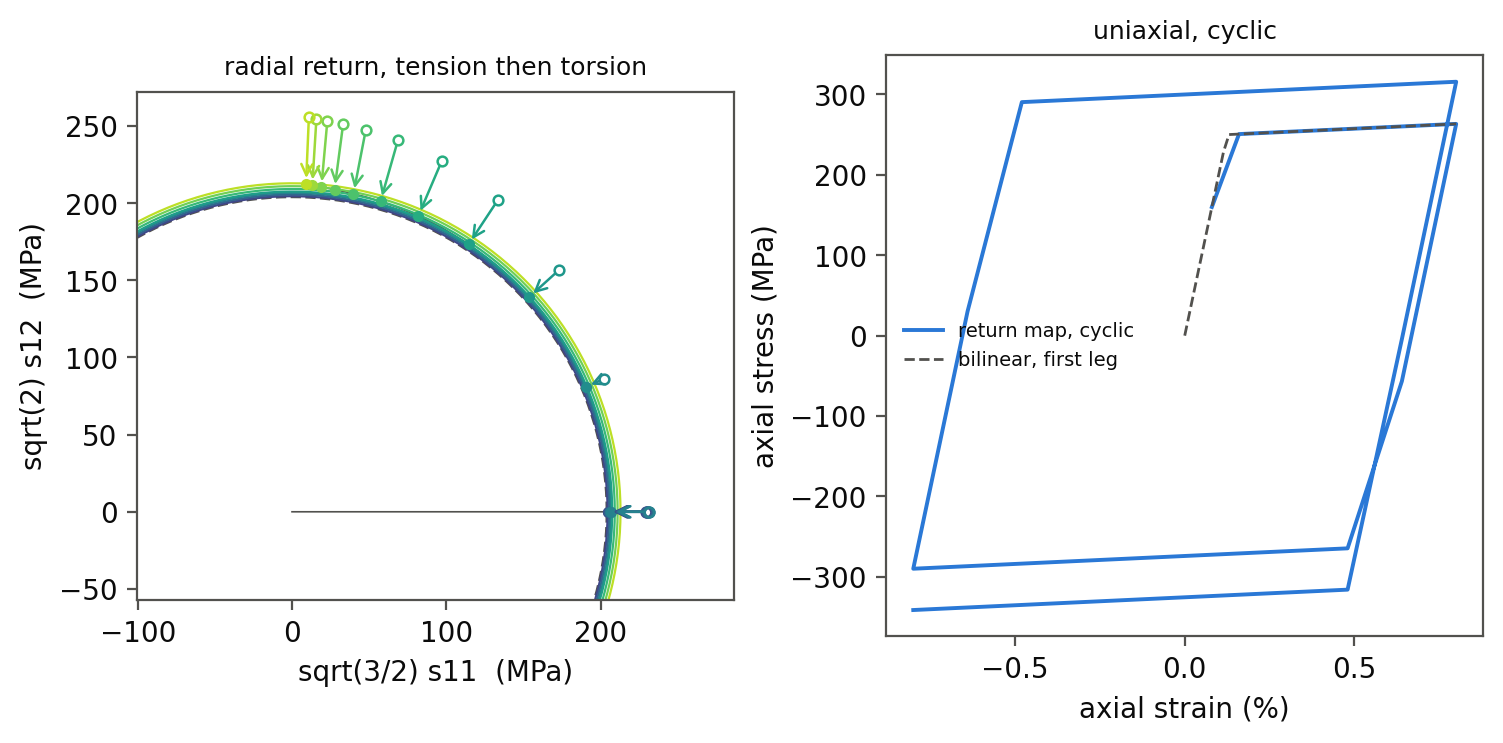
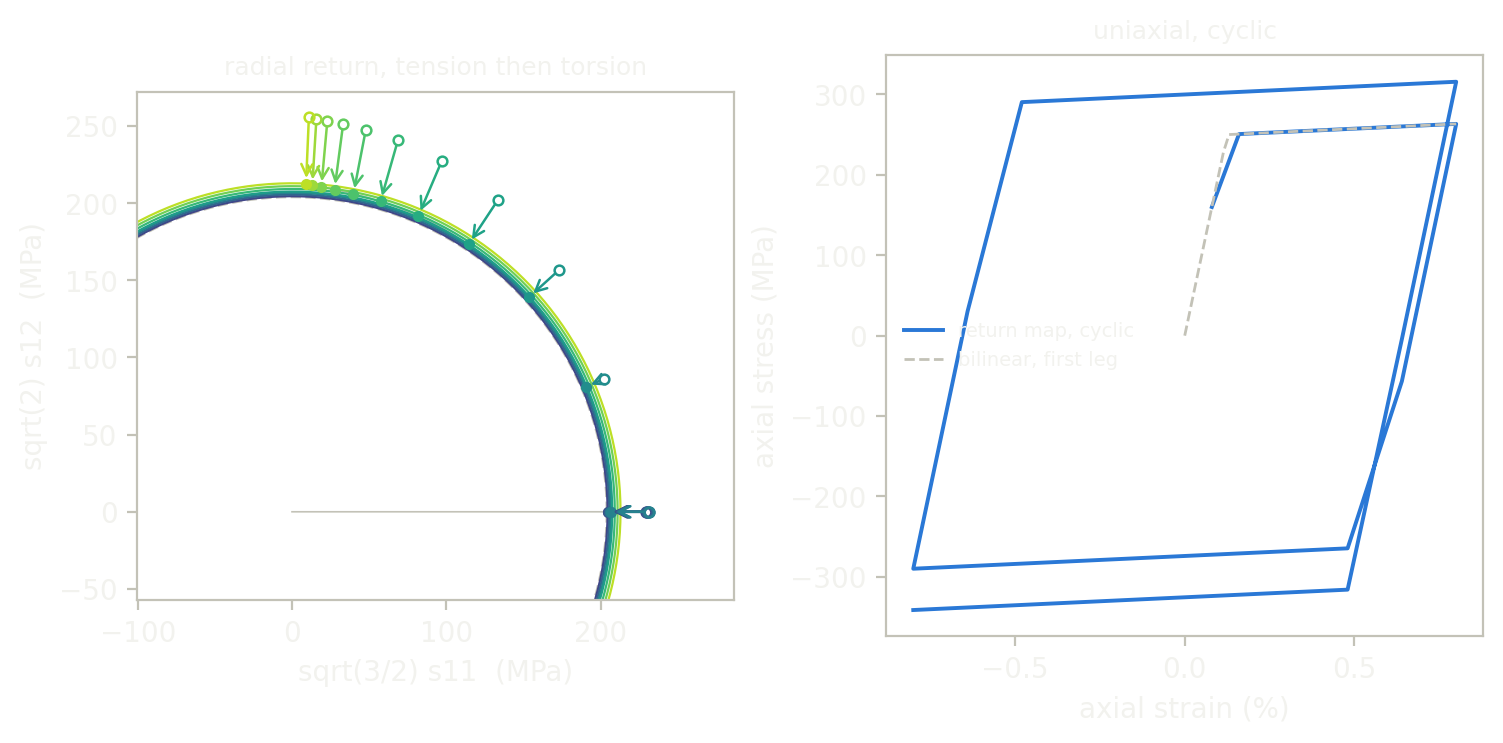

In [11]:
import matplotlib.pyplot as plt

# the cyclic loop: stress at each reversal, and the plastic strain range of each half-cycle (axial strain minus the elastic part)
pc = len(AMPS) + 3                                          # cyclic, amplitude 0.008
reversal = [NSTEP // 4 - 1, NSTEP // 2 - 1, 3 * NSTEP // 4 - 1, NSTEP - 1]
plastic_strain = driving[pc] - resp[pc] / E_MOD
peaks = resp[pc][reversal]
ranges = np.abs(np.diff(plastic_strain[reversal]))
print("stress at the four reversals (MPa):", peaks.round(0))
print("plastic strain range of the second, third and fourth half-cycles:", ranges.round(5), "(falling)")
assert (np.abs(peaks[1:]) > np.abs(peaks[0])).all() and (np.diff(np.abs(peaks)) > 0).all() and (np.diff(ranges) < 0).all()

# the tension-torsion path through the deviatoric plane, with the same kernel, one step at a time
leg = NSTEP // 2
e11 = AMP_NP * np.minimum(np.arange(1, NSTEP + 1) / leg, 1.0)
e12 = AMP_NP * np.maximum((np.arange(1, NSTEP + 1) - leg) / leg, 0.0)
path6 = np.zeros((NSTEP, 6)); path6[:, 0] = e11; path6[:, 3] = e12
bar_run = {k: np.asarray(v) for k, v in points.run(path=np.array([0], np.int32), d_eps=np.zeros((6, 1)), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD, strain=path6.reshape(-1)).items()}
s11 = bar_run["axial"][:, 0] - KAPPA * e11                  # the deviator: sigma11 = s11 + kappa tr(eps)
s12 = bar_run["shear"][:, 0]
u, v = np.sqrt(1.5) * s11, np.sqrt(2.0) * s12               # in this plane the surface is a circle and the norm is hypot(u, v)
radius = np.hypot(u, v)
prev_u, prev_v = np.r_[0.0, u[:-1]], np.r_[0.0, v[:-1]]
d11, d12 = np.diff(np.r_[0.0, e11]), np.diff(np.r_[0.0, e12])
trial_u = prev_u + np.sqrt(1.5) * 2 * MU * (2.0 / 3.0) * d11     # the elastic predictor: previous deviator plus 2 mu dev(strain increment)
trial_v = prev_v + np.sqrt(2.0) * 2 * MU * d12
trial_radius = np.hypot(trial_u, trial_v)
plastic_now = trial_radius > radius + 1e-9
cross = np.abs(u * trial_v - v * trial_u)                   # the return is along the radius: the returned point is parallel to the trial point
assert cross[plastic_now].max() < 1e-6 * radius.max() ** 2, cross.max()
assert plastic_now.any() and (trial_radius[plastic_now] > radius[plastic_now]).all()
print(f"tension-torsion path, {NSTEP} steps: {int(plastic_now.sum())} plastic; the yield circle grows from radius {SQ23 * SIGMA_Y:.0f} to {radius[-1]:.0f} MPa")

fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.6), gridspec_kw={"width_ratios": [1.0, 1.0]}, constrained_layout=True)
colours = plt.cm.viridis(np.linspace(0.0, 0.9, NSTEP))
theta = np.linspace(0, 2 * np.pi, 200)
left.plot(SQ23 * SIGMA_Y * np.cos(theta), SQ23 * SIGMA_Y * np.sin(theta), "--", lw=1.0, color="#898781")
for k in range(NSTEP):
    if plastic_now[k] and (k % 5 == 4 or k == NSTEP - 1):
        left.plot(radius[k] * np.cos(theta), radius[k] * np.sin(theta), lw=0.8, color=colours[k])
shown = [k for k in range(NSTEP) if plastic_now[k] and k % 2 == 1]
for k in shown:
    left.annotate("", xy=(u[k], v[k]), xytext=(trial_u[k], trial_v[k]), arrowprops=dict(arrowstyle="->", lw=0.9, color=colours[k]))
    left.plot(trial_u[k], trial_v[k], "o", ms=3.5, mfc="none", mec=colours[k], mew=0.9)
    left.plot(u[k], v[k], "o", ms=3, color=colours[k])
left.plot(np.r_[0.0, u], np.r_[0.0, v], "-", lw=0.6, color="#898781", zorder=0)
lim = 1.12 * trial_radius.max()
left.set_xlim(-lim * 0.35, lim); left.set_ylim(-lim * 0.2, lim * 0.95); left.set_aspect("equal")
left.set_xlabel("sqrt(3/2) s11  (MPa)"); left.set_ylabel("sqrt(2) s12  (MPa)"); left.set_title("radial return, tension then torsion", fontsize=9)
right.plot(driving[pc] * 100, resp[pc], "-", lw=1.4, color="#2a78d6", label="return map, cyclic")
x1 = np.linspace(0, AMPS[3], 50)
right.plot(x1 * 100, np.where(x1 < EPS_Y, E_MOD * x1, SIGMA_Y + E_T * (x1 - EPS_Y)), "--", lw=1.0, color="#898781", label="bilinear, first leg")
right.set_xlabel("axial strain (%)"); right.set_ylabel("axial stress (MPa)"); right.set_title("uniaxial, cyclic", fontsize=9)
right.legend(frameon=False, fontsize=7)
show(fig, f"Two panels. Left: the deviatoric plane of a tension-then-torsion path, with the von Mises surface as circles. A dashed circle of radius {SQ23 * SIGMA_Y:.0f} megapascals is the initial surface; the stress point first moves out along the horizontal axis, then upward, and the surface grows to a radius of {radius[-1]:.0f}. Each step is an open dot outside the current circle and an arrow along the radius back to a filled dot on the grown circle, coloured by step. Right: the cyclic uniaxial stress-strain loop at {AMPS[3] * 100:.1f} percent strain. Stress rises to {SIGMA_Y:.0f} megapascals, bends onto a shallow hardening line, unloads elastically, yields in compression and repeats; the reversal stresses climb from {abs(peaks[0]):.0f} to {abs(peaks[-1]):.0f} while the loop narrows, and the dashed bilinear line lies on the first loading leg.")

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays: 20 000 cyclic points with amplitudes drawn between 0.002 and 0.012. Each must still reproduce the one-dimensional model to 1e-8 MPa and finish every plastic return on the yield surface.

In [12]:
if gpu_available():
    many = 20_000
    rng = np.random.default_rng(3)
    amp_many = rng.uniform(0.002, 0.012, many)
    big_hist, big_ref, _ = histories("cyclic", amp_many)
    got = points.run(path=xp.arange(many, dtype=xp.int32), d_eps=xp.zeros((6, many)), E=E_MOD, nu=NU, sigma_y=SIGMA_Y, hard=HARD, strain=xp.asarray(big_hist.reshape(-1)))
    assert on_device(got["stress"]), "the result is a device array: the kernel ran on the GPU"
    gap_gpu = np.abs(to_numpy(got["axial"]).T - big_ref).max()
    assert gap_gpu < 1e-8 and float(to_numpy(got["off_surface"]).max()) < 1e-12, gap_gpu
    print(f"{many} cyclic integration points on the GPU: worst stress gap to the one-dimensional model {gap_gpu:.1e} MPa; every return on the surface")
else:
    print("no GPU here; the sweep stays at", NP, "integration points")

20000 cyclic integration points on the GPU: worst stress gap to the one-dimensional model 1.5e-12 MPa; every return on the surface


## What just happened

- `Material` named the strain history, the tangent probe and the four constants once; `update` is the radial return, with a natural `if / else` on the trial yield function, and one lane is one integration point. It plays the role of the per-point routine of a finite-element code, as in [Finite elements](07_fem_assembly), where one lane is one corner of a triangle.
- The three-dimensional return map reproduced the one-dimensional uniaxial model and the scalar shear model for every point and step, and the first leg followed the closed-form bilinear curve.
- Every plastic return ended on the yield surface (by construction), the plastic strain stayed traceless (by construction), and the lateral stress vanished on the uniaxial paths.
- `jvp` gave the consistent tangent. It matched central differences and the closed form of Simo and Taylor, for plastic and for elastic last steps. Its shear columns are in tensor shear: halve them for an engineering-shear code.
- On a non-proportional path (tension then torsion) the error of the final stress fell as the step count to the power 1.01: backward Euler is first order, and the proportional paths above hide that because the return is exact there.
- Newton on the lateral strains of the last step, solved to end laterally stress-free as a mixed-control driver does, converged in three iterations with the consistent tangent, each residual about the square of the last, and in a dozen with the elastic stiffness.
- `m.eigh` gave the principal stresses of the last step, and the von Mises stress from them equalled the one from the deviator to rounding.
- The picture is the algorithm: trial points outside the growing yield circle in the deviatoric plane, each returned along the radius, beside the cyclic loop, which gets taller and narrower as isotropic hardening grows the elastic range.

## Try this

Set `HARD = 0` for perfect plasticity and watch the hardening line go flat; the tangent after yield then loses its `H` term, and the checks above stay as they are. Or add a probe at an earlier step by moving the `NSTEP - 1` in `strain_at`, to see how a past strain changes the stress now.

## Next

[Finite elements](07_fem_assembly) shows the lane-per-corner layout this routine runs in, and [Reverse a whole rollout](05_tapes_and_events) covers gradients through many steps rather than the last one.